In [45]:
import matplotlib.pyplot as plt
import numpy as np

In [46]:
def plot_embeddings(embeddings_2d, labels, round):
    embeddings_2d = np.array(embeddings_2d)
    labels = np.array(labels)

    print("Embeddings shape:", embeddings_2d.shape)
    print("Labels shape:", labels.shape)

    # Plot the embeddings
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.7)

    # Add legend
    legend = plt.legend(*scatter.legend_elements(), title="Classes")
    plt.gca().add_artist(legend)

    plt.title(f"2D Embedding Space (PCA) - round {round}")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.show()

In [47]:
def plot_markers(vectors_s_2d, markers, similar_prototypes_2d, dissimilar_prototypes_2d, round):
    n_pairs = 100
    # Plot the vectors `s` in 2D, using green for similar pairs and red for dissimilar pairs
    plt.figure(figsize=(10, 7))
    for i, marker in enumerate(markers):
        color = 'green' if marker == 1 else 'red'
        plt.scatter(vectors_s_2d[i, 0], vectors_s_2d[i, 1], color=color, alpha=0.7)

    # Plot the prototypical vectors as large crosses
    plt.scatter(similar_prototypes_2d[:, 0], similar_prototypes_2d[:, 1],
                color='green', marker='x', s=200, label='Similar Prototypes')

    plt.scatter(dissimilar_prototypes_2d[:, 0], dissimilar_prototypes_2d[:, 1],
                color='red', marker='x', s=200, label='Dissimilar Prototypes')

    # Add title and labels
    plt.title(f"2D Plot of {n_pairs} Sample Pairs with Prototypical Vectors - round {round}")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")

    # Add a legend for clarity
    plt.legend()

    # Show plot
    plt.show()

In [48]:
embeddings_2d_round_0 = [[ 1.48222998e-01,  5.37642352e-02],
 [-2.68948108e-01,  4.74215820e-02],
 [ 1.81806013e-02, -6.64738268e-02],
 [ 4.06865150e-01, -2.03155294e-01],
 [ 4.37932670e-01, -1.75302420e-02],
 [ 3.27880979e-01,  8.14601108e-02],
 [ 2.30178937e-01, -2.67985851e-01],
 [-9.87788588e-02,  7.33150318e-02],
 [ 1.00174285e-02,  3.04904222e-01],
 [ 6.50303364e-02,  1.59523174e-01],
 [-1.97967678e-01,  2.30846062e-01],
 [-2.65931815e-01,  1.23555876e-01],
 [ 1.39915347e-01, -3.31527859e-01],
 [-4.70692664e-01,  1.04725830e-01],
 [-1.07540086e-01,  1.15398325e-01],
 [ 4.00021113e-03, -7.25096241e-02],
 [-2.90252924e-01, -3.42792988e-01],
 [-1.85076401e-01,  3.42452317e-01],
 [-9.91772115e-02, -9.29146707e-02],
 [-1.14780314e-01,  2.74732739e-01],
 [ 1.16665773e-01,  8.22922960e-02],
 [-3.64942430e-03,  9.56134573e-02],
 [ 3.48356605e-01, -2.15546981e-01],
 [-1.96723163e-01, -4.82791588e-02],
 [ 5.36110401e-02,  2.11127013e-01],
 [ 1.40431240e-01,  4.05567259e-01],
 [-2.68689413e-02,  4.12992109e-03],
 [ 1.49625450e-01,  4.96843979e-02],
 [-8.08581151e-03,  4.28251922e-02],
 [-1.53197259e-01, -3.48418802e-01],
 [-1.35672204e-02, -4.36639152e-02],
 [ 2.22812772e-01, -1.81856498e-01],
 [ 3.12193006e-01,  2.26003319e-01],
 [-9.28121060e-02, -2.62275338e-01],
 [-1.55904725e-01, -1.27123035e-02],
 [ 3.72946143e-01, -9.03405342e-03],
 [ 1.57054320e-01, -1.12612657e-01],
 [ 4.17775899e-01,  4.08268683e-02],
 [-1.09506942e-01,  4.92198095e-02],
 [ 4.40413922e-01, -6.67003393e-01],
 [ 1.92663938e-01,  4.23716418e-02],
 [ 4.60096002e-02, -1.71768174e-01],
 [ 5.54971807e-02,  7.04430938e-02],
 [ 2.33539611e-01,  1.94831073e-01],
 [-2.71116775e-02,  1.27892092e-01],
 [-7.19357729e-02,  2.40676731e-01],
 [ 2.57434577e-01, -8.72433782e-02],
 [-1.10834979e-01, -1.79015055e-01],
 [-1.01483390e-01, -2.36700028e-01],
 [-2.65221775e-01, -4.11604419e-02],
 [-2.73001879e-01, -4.57333744e-01],
 [-2.10159332e-01, -2.16636211e-01],
 [-4.65639532e-02,  3.89504135e-02],
 [-6.17897436e-02,  1.52147606e-01],
 [ 1.48541465e-01, -9.53028798e-02],
 [ 1.87014148e-01,  1.72729239e-01],
 [ 4.63750273e-01, -7.89194927e-02],
 [ 4.88023281e-01,  2.34736711e-01],
 [ 6.87641576e-02, -2.85021931e-01],
 [ 2.98940241e-01, -2.80974060e-01],
 [-4.30739790e-01,  2.20607042e-01],
 [-1.70209873e-02,  1.00532547e-01],
 [-1.68469593e-01,  1.24707408e-01],
 [ 2.82414824e-01, -8.09889883e-02],
 [-7.68334717e-02,  2.13519424e-01],
 [ 2.21503839e-01, -2.40682270e-02],
 [-1.29154235e-01, -1.74305618e-01],
 [-1.03553630e-01, -7.38230944e-02],
 [-2.55027145e-01,  7.59103820e-02],
 [-1.64514959e-01,  1.06626814e-02],
 [-1.85962632e-01,  1.43881112e-01],
 [ 2.92294413e-01, -1.47688925e-01],
 [-6.78649992e-02, -2.71430939e-01],
 [-2.52069026e-01, -8.93374234e-02],
 [-2.00289890e-01, -9.79821011e-02],
 [ 4.85097647e-01, -4.24104065e-01],
 [ 5.45993626e-01, -7.11710155e-02],
 [-1.77044705e-01, -2.97473103e-01],
 [ 7.82408491e-02, -1.98126331e-01],
 [-5.97816296e-02, -6.72860667e-02],
 [-5.71403876e-02, -4.06591833e-01],
 [ 3.61373782e-01, -5.13069510e-01],
 [-2.17539072e-02, -1.50211513e-01],
 [ 4.97901365e-02,  1.69917997e-02],
 [-2.80300111e-01, -2.27208346e-01],
 [ 7.99697414e-02,  2.29395628e-01],
 [-3.89696956e-02, -1.05152816e-01],
 [-1.18345998e-01,  1.88256472e-01],
 [-6.46431446e-02, -1.90857751e-03],
 [-5.37717342e-02, -7.21452907e-02],
 [ 1.35330006e-01,  8.96497369e-02],
 [ 2.65390426e-01, -1.96684897e-01],
 [ 6.82512224e-02,  1.55242279e-01],
 [ 3.67327064e-01, -2.68429145e-02],
 [-3.68747801e-01,  5.90163730e-02],
 [ 3.98514479e-01,  1.51080370e-01],
 [-4.72808145e-02,  3.00699353e-01],
 [ 9.47747827e-02, -1.89517532e-02],
 [ 4.34957385e-01,  1.01037472e-02],
 [-2.40407467e-01,  7.98675418e-02],
 [ 2.34707236e-01, -1.76874861e-01],
 [ 1.86602816e-01,  1.02580421e-01],
 [-1.01348884e-01, -4.91439132e-03],
 [ 4.21703188e-03,  1.01437904e-01],
 [-2.25150548e-02,  4.85695243e-01],
 [-1.94910690e-01, -1.89911351e-01],
 [-9.96372476e-02, -1.65603533e-01],
 [-2.03679919e-01, -2.49810144e-01],
 [ 1.08378439e-03,  7.70856589e-02],
 [-4.63542342e-01,  1.42075986e-01],
 [-2.50973672e-01, -2.55579114e-01],
 [-9.79152024e-02, -6.43935874e-02],
 [ 8.38330984e-02,  6.82438239e-02],
 [-7.84222856e-02, -2.83206925e-02],
 [ 3.44496369e-01,  3.39612991e-01],
 [ 2.85418659e-01, -8.59894156e-02],
 [-1.53132722e-01,  2.22068012e-01],
 [ 2.02027351e-01,  7.63113946e-02],
 [ 4.61333431e-02,  8.34021941e-02],
 [-6.41904771e-02,  1.19471122e-02],
 [ 4.39107716e-01,  1.52671725e-01],
 [-1.95239410e-02, -3.02001029e-01],
 [ 2.69246221e-01,  2.19006002e-01],
 [ 9.87176672e-02,  3.51522624e-01],
 [-1.87120557e-01, -3.75855386e-01],
 [-1.11186097e-03, -2.05729887e-01],
 [-2.70181987e-02, -1.13307722e-02],
 [-2.54058421e-01,  8.85985792e-02],
 [-6.68344414e-03,  8.55154321e-02],
 [-5.26612289e-02,  2.05512799e-04],
 [-3.19160521e-01,  2.10103422e-01],
 [-1.60849467e-01, -2.63186663e-01],
 [-1.22019321e-01,  2.58452535e-01],
 [-2.12137267e-01,  1.39516518e-01],
 [ 1.15698434e-01, -1.87715277e-01],
 [-2.89232820e-01, -1.42454028e-01],
 [-1.71122923e-01,  4.44149859e-02],
 [-1.78911179e-01, -5.38273528e-02],
 [-1.30199388e-01, -1.30486876e-01],
 [-2.89498538e-01,  3.69000994e-02],
 [-9.40235797e-03,  2.16752112e-01],
 [-2.48763695e-01, -1.16335139e-01],
 [ 1.29989639e-03,  4.74846512e-01],
 [ 3.63414139e-01,  4.96354908e-01],
 [ 3.77336860e-01,  2.08793879e-01],
 [ 2.55644810e-03,  3.11375022e-01],
 [ 9.76822688e-04,  2.79894937e-02],
 [ 6.91932067e-02,  1.00582063e-01],
 [-4.57258582e-01,  1.09181091e-01],
 [ 2.61185199e-01,  5.57158403e-02],
 [ 6.51900992e-02,  1.06053695e-01],
 [-7.33518824e-02, -1.88846625e-02],
 [ 2.35494860e-02,  1.14598349e-01],
 [-1.19069859e-01, -3.59269716e-02],
 [-3.96295667e-01,  5.92395402e-02],
 [-1.90434486e-01, -1.64487973e-01],
 [-2.57496327e-01, -1.00232504e-01],
 [-3.92908342e-02,  3.58117163e-01],
 [ 2.90570170e-01, -2.22212210e-01],
 [ 3.72262038e-02, -5.85541949e-02],
 [-1.81703195e-01, -9.31956321e-02],
 [-1.48306638e-01,  9.38884169e-02],
 [-5.54261915e-02,  1.09145911e-02],
 [ 2.01189786e-01,  4.50168960e-02],
 [-2.31702149e-01,  3.30340154e-02],
 [-3.08752030e-01,  7.75249749e-02],
 [-3.78009021e-01,  3.73985410e-01],
 [-2.77970761e-01, -1.03996575e-01],
 [ 8.65932107e-02, -1.12523161e-01],
 [-2.15514019e-01, -8.82102549e-02],
 [ 8.46028507e-01,  2.58082122e-01],
 [-1.23798840e-01,  2.25124642e-01],
 [ 1.03045322e-01, -7.91574270e-02],
 [ 1.50594160e-01,  2.27950260e-01],
 [-1.81741238e-01, -1.85735859e-02],
 [ 7.72739649e-02, -2.61251852e-02],
 [ 5.25349751e-02, -1.14261404e-01],
 [ 2.38672078e-01,  5.65373972e-02],
 [-1.28852919e-01,  2.63460306e-03],
 [-1.07706347e-02, -4.20084223e-02],
 [-3.43829840e-02,  1.38720706e-01],
 [-8.15029740e-02, -4.29286569e-01],
 [-2.29877353e-01, -2.05342934e-01],
 [-3.06559682e-01,  8.40887576e-02],
 [-1.40015140e-01,  1.46380350e-01],
 [ 1.62069708e-01,  4.25623626e-01],
 [ 9.27084386e-02, -2.30842531e-01],
 [-2.11602032e-01, -1.13539405e-01],
 [-1.27345696e-01, -7.55117333e-04],
 [ 3.21084887e-01,  1.79073751e-01],
 [-1.58910424e-01,  1.32666215e-01],
 [ 5.99263757e-02, -5.27035534e-01],
 [-3.83603722e-02, -1.05919614e-01],
 [-2.66887575e-01, -1.58740208e-01],
 [-2.74035662e-01,  3.12847316e-01],
 [-1.53029621e-01,  8.77527297e-02],
 [-7.82777816e-02,  1.03042368e-02],
 [ 1.00456774e-01, -1.68075368e-01],
 [ 5.29029191e-01,  6.72542676e-02],
 [-1.44533306e-01,  2.13526756e-01],
 [ 9.81827080e-02, -7.96506107e-02],
 [-2.26813763e-01,  1.89676687e-01],
 [ 5.29595256e-01,  1.79707274e-01],
 [-3.35478485e-02,  2.17140809e-01],
 [ 7.00703785e-02, -3.34971696e-02],
 [-3.50879468e-02, -1.13063850e-01],
 [ 7.22784281e-01, -3.79406065e-02],
 [-1.93517864e-01,  1.06227502e-01],
 [ 1.51921540e-01, -8.69618431e-02],
 [ 9.07889158e-02,  2.09761679e-01],
 [-3.34590614e-01,  2.97216713e-01],
 [-1.41684532e-01, -9.43158492e-02],
 [ 3.38872433e-01, -1.60301998e-01],
 [ 6.07070997e-02, -2.60004699e-01],
 [ 4.08120841e-01, -1.30670741e-01],
 [ 1.46203982e-02, -9.57540125e-02],
 [-1.15307897e-01, -2.17272088e-01],
 [-3.43906805e-02, -6.56227693e-02],
 [ 4.73187538e-03, -3.08927864e-01],
 [ 3.91775578e-01,  1.92107841e-01],
 [-1.89950466e-02,  1.07337497e-01],
 [-3.32791030e-01, -1.20845899e-01],
 [ 8.73002827e-01,  3.07135373e-01],
 [-9.40400884e-02, -1.77566513e-01],
 [-1.05330840e-01,  1.42161503e-01],
 [-3.87655050e-02,  3.87601517e-02],
 [-5.68108307e-03, -2.69379497e-01],
 [ 2.10732833e-01,  3.09219718e-01],
 [-2.62234539e-01, -2.58325756e-01],
 [ 2.40825444e-01, -5.15155774e-03],
 [ 1.51565477e-01, -1.53917953e-01],
 [-1.04932696e-01, -4.21975106e-01],
 [-3.38996112e-01,  5.44320457e-02],
 [ 4.06738549e-01, -5.31839021e-03],
 [ 4.19783369e-02,  3.22097570e-01],
 [ 1.22734554e-01,  2.12483913e-01],
 [-1.22810453e-01,  2.17128739e-01],
 [-3.41482386e-02,  1.65756643e-01],
 [ 3.61890376e-01,  3.00945431e-01],
 [-1.49387971e-01, -1.00256607e-01],
 [ 1.21062063e-01,  1.12064794e-01],
 [ 5.34837469e-02, -1.67501763e-01],
 [-1.77641794e-01,  8.61232448e-03],
 [ 1.46126732e-01,  2.05201413e-02],
 [-2.40708694e-01, -3.16752493e-01],
 [-1.16237119e-01,  1.24755785e-01],
 [-2.74181753e-01,  1.05835311e-01],
 [-1.64589331e-01,  2.46465877e-01],
 [ 1.40008941e-01,  2.57515222e-01],
 [-9.12061483e-02,  3.26799959e-01],
 [-1.38458163e-01, -2.93267965e-01],
 [ 2.64405161e-01,  2.48463929e-01],
 [-2.18349397e-01,  1.21135451e-01],
 [-1.80858433e-01,  1.91726089e-01],
 [ 1.18511729e-01,  7.09528029e-02],
 [ 1.96235597e-01,  2.78423369e-01],
 [ 1.34885401e-01, -1.07432440e-01],
 [-7.08237067e-02, -1.79849461e-01],
 [-1.78299159e-01,  7.52486214e-02],
 [ 2.54294127e-01, -1.51710466e-01],
 [-1.41221836e-01, -2.83687443e-01],
 [ 1.61078155e-01, -1.15435764e-01],
 [-4.83224481e-01,  2.22379699e-01],
 [-1.06600247e-01, -1.22274607e-01],
 [ 1.01339713e-01,  2.48433009e-01],
 [-6.21184846e-03,  3.56950164e-01],
 [-1.20505862e-01, -2.76791185e-01],
 [-2.62044787e-01, -4.13396582e-02],
 [ 1.28585652e-01, -1.22914307e-01],
 [ 2.50396952e-02,  1.47492722e-01],
 [ 2.55136602e-02, -3.18941399e-02],
 [-2.61952817e-01,  2.20789418e-01],
 [-2.75607228e-01,  1.49985418e-01],
 [-2.74556667e-01, -1.14048012e-01],
 [-3.77197601e-02,  2.80679405e-01],
 [ 3.58380258e-01,  5.19081473e-01],
 [-1.73455805e-01, -2.79703915e-01],
 [-3.60713154e-01,  1.21290255e-02],
 [-2.31407195e-01,  2.88576871e-01],
 [ 3.56620520e-01, -1.26165347e-02],
 [-1.58912420e-01,  7.79607566e-03],
 [ 8.83368701e-02, -1.98835567e-01],
 [-2.23939970e-01, -2.36035123e-01],
 [ 2.31553670e-02,  2.10433304e-01],
 [-3.31251502e-01,  2.75863037e-02],
 [ 1.45593256e-01, -6.06873572e-01],
 [-1.04783736e-01, -1.23445094e-01],
 [ 5.21239877e-01, -8.60387310e-02],
 [-1.22047789e-01,  1.51485562e-01],
 [-2.81906307e-01, -1.35251969e-01],
 [ 4.04192358e-02,  2.85447270e-01],
 [ 1.62605137e-01, -1.07383877e-01],
 [-1.17103182e-01,  1.59967661e-01],
 [-1.23649269e-01, -1.13012068e-01],
 [-2.11947009e-01, -3.49360168e-01],
 [ 3.40957195e-02,  2.36144885e-02],
 [-3.20484281e-01, -1.44787982e-01],
 [-3.60668711e-02, -3.42679024e-01],
 [ 5.59021011e-02, -5.77809773e-02],
 [-1.22046001e-01,  2.64162749e-01],
 [-9.19330120e-02,  1.82228178e-01],
 [-1.08209580e-01,  5.44362776e-02],
 [ 3.61094892e-01,  9.29706693e-02],
 [-3.02998442e-02,  6.40557706e-02],
 [-2.62520164e-01,  4.24506426e-01],
 [ 1.57654777e-01,  3.76593731e-02],
 [ 5.88173151e-01, -1.38802662e-01],
 [ 2.43001077e-02,  2.43739754e-01],
 [ 3.76656264e-01, -1.61098763e-01],
 [ 3.30476493e-01, -3.44705343e-01],
 [-3.62914130e-02, -1.38554145e-02],
 [ 4.69308309e-02, -8.46637115e-02],
 [ 2.16439694e-01, -9.96598154e-02],
 [-8.79730955e-02,  5.11655882e-02],
 [ 2.06172466e-01,  1.57811627e-01],
 [-1.35779902e-01, -2.58184373e-01],
 [-2.37926543e-01, -7.70638511e-02],
 [-1.41833156e-01,  1.77514911e-01],
 [-3.21641982e-01,  2.79906839e-01],
 [-2.77288347e-01, -2.45226249e-01],
 [-2.51772515e-02, -3.48777682e-01],
 [ 6.47234380e-01,  4.56744507e-02],
 [-3.13541740e-01, -2.97431827e-01],
 [-4.22072053e-01,  1.21334083e-01],
 [ 1.41926214e-01, -2.23913580e-01],
 [-3.74159664e-01, -1.05110276e-02],
 [ 8.55052248e-02, -9.84003246e-02],
 [ 6.24113269e-02,  2.18671352e-01],
 [-2.58033901e-01,  1.61148280e-01],
 [-2.24483103e-01, -1.43255204e-01],
 [ 1.19900741e-01,  1.18381813e-01],
 [-1.30073041e-01, -1.29354760e-01],
 [-3.58532108e-02, -1.35850608e-01],
 [-6.71725050e-02, -5.96642867e-02],
 [ 1.11963652e-01,  1.58501998e-01],
 [ 2.15976462e-01, -6.44532204e-01],
 [-1.34732917e-01, -2.22410381e-01],
 [-1.70595553e-02, -3.23105216e-01],
 [ 3.89178358e-02,  2.08603889e-01],
 [-2.33928055e-01,  5.51304594e-02],
 [-6.63244650e-02,  3.19669932e-01],
 [ 1.67455405e-01,  2.05690395e-02],
 [-3.94287974e-01,  2.69718081e-01],
 [-3.79161865e-01, -2.64405996e-01],
 [-1.16721585e-01,  6.23234399e-02],
 [ 8.71214271e-02, -2.37153217e-01],
 [-1.76399108e-02,  3.42364043e-01],
 [ 3.07752997e-01, -2.45990008e-01],
 [ 1.02824770e-01, -1.83886699e-02],
 [ 5.11366546e-01,  6.30231276e-02],
 [ 1.25868917e-01,  3.46433252e-01],
 [ 1.49429599e-02,  1.58332795e-01],
 [ 4.05105203e-01, -4.98241425e-01],
 [ 1.45357519e-01,  1.49740532e-01],
 [ 3.39748478e-03, -1.78162321e-01],
 [ 1.99623629e-01, -4.03923780e-01],
 [ 2.65159216e-02,  2.17026979e-01],
 [-1.21148176e-01,  1.22264601e-01],
 [ 2.63275229e-03,  2.70683974e-01],
 [-6.66403249e-02,  1.68239906e-01],
 [-2.24455670e-01, -1.03302062e-01],
 [-2.69709706e-01, -3.91512066e-01],
 [-2.64672309e-01, -1.40242353e-01],
 [-3.60598892e-01, -1.96705684e-01],
 [ 8.99565443e-02,  4.86358143e-02],
 [ 1.45671859e-01,  2.51819231e-02],
 [ 8.15713629e-02, -7.67214075e-02],
 [ 1.30064890e-01, -4.85883951e-02],
 [-6.50996866e-04, -2.59288013e-01],
 [ 1.75851732e-01, -4.44283068e-01],
 [-6.31518960e-02, -3.22650343e-01],
 [ 2.50382163e-02, -1.54651240e-01],
 [ 2.73802783e-02,  1.81323975e-01],
 [ 5.65893531e-01,  2.71087475e-02],
 [-3.57602350e-02,  5.77481575e-02],
 [-1.82730138e-01,  2.91266173e-01],
 [ 2.23111078e-01,  1.42838538e-01],
 [ 1.02213882e-02, -3.36289316e-01],
 [-1.58387721e-01, -1.90273657e-01],
 [ 5.59039414e-01,  4.40569848e-01],
 [-4.00914580e-01,  5.68063289e-04],
 [ 2.17266992e-01,  8.65861177e-02],
 [-1.45800978e-01,  3.02852213e-01],
 [-1.56905517e-01,  1.34427682e-01],
 [ 3.24015588e-01,  9.47836190e-02],
 [-3.47717077e-01,  1.83519557e-01],
 [-3.32464911e-02,  1.41968757e-01],
 [-1.30808167e-02,  2.92171210e-01],
 [-9.28993523e-02, -3.13444249e-02],
 [-2.50227392e-01,  3.56164098e-01],
 [-1.80346072e-01,  1.61393002e-01],
 [ 2.37010345e-02,  7.28219375e-02],
 [-4.98139411e-02,  9.67227072e-02],
 [-3.98097724e-01,  2.14225531e-01],
 [-2.18851119e-01, -2.19354212e-01],
 [-2.42077559e-01,  1.65953383e-01],
 [-1.69044212e-01, -5.17443158e-02],
 [-1.54013738e-01, -1.21027611e-01],
 [ 1.09234437e-01,  1.60744593e-01],
 [-1.33217856e-01,  3.01822633e-01],
 [-2.06395149e-01, -2.07826972e-01],
 [ 4.46231551e-02, -1.18298084e-01],
 [ 2.85137773e-01,  1.32592052e-01],
 [-1.90578029e-01, -6.07229352e-01],
 [ 6.82175159e-02, -3.59072894e-01],
 [-2.31303692e-01, -2.07354039e-01],
 [-8.19337219e-02,  3.61586064e-01],
 [ 1.89761564e-01, -1.06409431e-01],
 [ 7.53777742e-01, -2.34694451e-01],
 [-2.01513469e-01,  1.63539127e-01],
 [ 5.41179180e-01, -1.38077796e-01],
 [ 1.58638239e-01, -5.72483875e-02],
 [ 4.40986037e-01,  1.18709765e-01],
 [ 8.89227763e-02, -9.52525288e-02],
 [ 2.66502023e-01,  1.49913669e-01],
 [-4.39854413e-02, -3.09993982e-01],
 [-3.73419956e-03, -4.62334864e-02],
 [-2.32274637e-01, -1.71296149e-02],
 [ 3.58945340e-01, -3.29757184e-02],
 [-2.61663496e-01, -7.14900792e-02]]

In [49]:
embeddings_2d_round_100 = [[-1.00080773e-01, -1.72938898e-01],
 [-1.84576070e+00, -2.45260522e-01],
 [ 4.44627047e+00, -4.88444299e-01],
 [ 7.63828233e-02,  4.63408887e-01],
 [-2.53368211e+00,  1.03834033e-01],
 [ 2.72831511e+00, -3.21205229e-01],
 [-1.73270261e+00, -3.84789519e-02],
 [-1.86233163e+00,  1.47731915e-01],
 [ 1.49885178e+00, -6.51136339e-01],
 [-1.46403837e+00,  2.45764535e-02],
 [-2.50020909e+00, -6.29489794e-02],
 [ 7.60435390e+00, -6.62108585e-02],
 [-3.50012630e-01,  3.09966743e-01],
 [-2.07799363e+00,  2.74711549e-01],
 [-1.98053563e+00,  4.56300467e-01],
 [-1.09165442e+00, -1.23324595e-01],
 [-1.18019223e+00,  2.16459587e-01],
 [ 1.35219455e+00, -4.47129101e-01],
 [-1.27606785e+00,  1.69707224e-01],
 [-2.45399261e+00, -2.21566305e-01],
 [-2.81987143e+00,  9.71567705e-02],
 [-1.08906031e+00, -1.83149844e-01],
 [-4.85483289e-01,  1.54654026e-01],
 [ 3.31674516e-01,  2.49856755e-01],
 [ 1.41632538e-02,  2.20146433e-01],
 [-1.70096374e+00, -9.36680883e-02],
 [-1.21086085e+00, -3.07910353e-01],
 [-1.34461725e+00,  7.87206441e-02],
 [-1.93481541e+00, -2.04563588e-01],
 [ 1.79405367e+00, -7.80769289e-02],
 [-6.35636151e-01, -2.58059621e-01],
 [-2.16862106e+00, -1.27191857e-01],
 [-3.24130505e-01,  1.84378833e-01],
 [ 2.30587220e+00, -1.50460720e-01],
 [-2.71255898e+00, -1.89709857e-01],
 [ 1.05990696e+00,  1.14147209e-01],
 [-6.03674114e-01,  1.76898409e-02],
 [ 5.13897955e-01, -4.60738897e-01],
 [-2.49442315e+00,  2.36546516e-01],
 [ 6.91270232e-01,  7.22316056e-02],
 [-2.56577492e+00,  2.75585383e-01],
 [-2.97841120e+00,  8.73076096e-02],
 [-9.55558345e-02,  6.81880638e-02],
 [-1.93663144e+00, -3.59814584e-01],
 [ 8.37599695e-01, -1.08952420e-02],
 [-2.45311022e+00,  1.14697732e-01],
 [-8.72984529e-01, -2.94576526e-01],
 [-6.93350315e-01, -2.73628742e-01],
 [ 2.30127716e+00,  2.32803658e-01],
 [-2.46957970e+00, -2.97681298e-02],
 [-1.14604700e+00, -1.46173507e-01],
 [-6.76618338e-01,  2.09091082e-01],
 [ 4.40173531e+00, -3.91922027e-01],
 [-1.91713512e+00,  3.07920635e-01],
 [ 1.85468554e-01, -2.05299616e-01],
 [-9.37032342e-01,  2.48644873e-01],
 [ 6.32003486e-01, -1.13628041e-02],
 [-9.19976115e-01, -4.29666698e-01],
 [-2.02822089e+00,  1.60214871e-01],
 [ 6.22894883e-01, -2.30805520e-02],
 [-2.52210069e-02, -6.84906662e-01],
 [-1.21770060e+00,  7.76147783e-01],
 [ 4.25675344e+00, -2.26257190e-01],
 [-3.24135840e-01,  8.22718516e-02],
 [ 8.94109821e+00,  5.71933031e-01],
 [-2.36663008e+00, -2.21788093e-01],
 [ 2.19829583e+00,  5.07349782e-02],
 [ 3.28460169e+00,  1.91782832e-01],
 [-1.25881389e-01,  4.14975226e-01],
 [-1.21359885e+00, -3.19038242e-01],
 [ 7.64872885e+00, -2.87608970e-02],
 [-8.60951364e-01, -1.33644314e-02],
 [-1.36946654e+00,  2.00350419e-01],
 [ 3.54799676e+00,  3.60906646e-02],
 [-1.62622166e+00, -8.11322853e-02],
 [-5.52537262e-01, -3.88770662e-02],
 [ 9.38920915e-01,  4.40787375e-02],
 [-1.91390276e+00,  3.13843638e-01],
 [ 1.78239465e+00,  1.01597428e+00],
 [ 1.70154786e+00, -1.79247305e-01],
 [ 4.99727869e+00, -2.51254231e-01],
 [-1.09842062e+00,  9.49931964e-02],
 [-2.22385359e+00, -1.67554602e-01],
 [ 4.00990152e+00, -2.02083096e-01],
 [-2.24462152e+00, -2.61897575e-02],
 [ 7.63014364e+00,  1.04936011e-01],
 [ 5.60273468e-01,  5.67761585e-02],
 [-1.32420385e+00,  4.24176842e-01],
 [ 1.85388410e+00,  6.21227324e-01],
 [-2.01012754e+00,  6.34117723e-02],
 [ 4.50084448e+00,  2.05045715e-02],
 [-1.30532038e+00,  3.53269875e-01],
 [ 2.67877388e+00,  3.08972150e-01],
 [-2.00411630e+00, -5.64533584e-02],
 [-2.90116787e+00, -3.40479538e-02],
 [-6.40533090e-01,  1.99718431e-01],
 [ 1.76722324e+00, -2.40102276e-01],
 [-2.54825544e+00, -1.71546981e-01],
 [ 2.06275031e-01, -1.48049399e-01],
 [-1.38708723e+00, -9.63037163e-02],
 [ 5.75786352e-01,  5.91423571e-01],
 [-1.92352965e-01,  9.69100557e-03],
 [-6.29510522e-01,  2.56313980e-02],
 [ 2.07205445e-01,  5.25153518e-01],
 [-1.89448848e-01, -6.52761608e-02],
 [ 7.88628280e-01,  8.24809968e-02],
 [-2.45859265e+00, -2.54792958e-01],
 [ 4.56899977e+00, -6.01266026e-02],
 [-1.99267161e+00,  3.49705935e-01],
 [ 1.49807441e+00,  1.35751124e-02],
 [ 3.81718612e+00,  4.39039953e-02],
 [ 1.74452162e+00,  9.01556760e-02],
 [-1.10349178e+00,  4.66173440e-01],
 [-4.44730401e-01, -8.84099007e-02],
 [-2.09852651e-01,  1.26272649e-01],
 [-9.29181695e-01, -2.75616199e-01],
 [ 4.31173563e-01, -3.47565055e-01],
 [-2.12855077e+00, -3.77534553e-02],
 [-1.00678790e+00, -1.59396961e-01],
 [-2.67301083e+00,  7.75233358e-02],
 [ 1.61575496e+00, -2.44831651e-01],
 [-1.33853877e+00, -1.83601409e-01],
 [-1.61360538e+00,  1.36266090e-02],
 [-7.27526367e-01, -4.19268943e-02],
 [-1.05560720e+00,  2.47314289e-01],
 [-3.00035858e+00,  7.69216102e-03],
 [-2.22607064e+00,  4.20558378e-02],
 [ 3.00796533e+00, -1.03728421e-01],
 [ 9.85433254e-03,  1.31335467e-01],
 [-3.03436741e-02, -5.86117916e-02],
 [ 1.24149871e+00, -4.75545704e-01],
 [-4.89705652e-01,  4.81471010e-02],
 [ 9.87052560e-01, -3.48062992e-01],
 [ 5.43519914e-01,  4.20589983e-01],
 [-1.68131411e+00,  1.20677695e-01],
 [ 9.34343040e-01, -3.04863870e-01],
 [ 7.97466218e-01, -1.38218746e-01],
 [ 2.46434227e-01, -1.04232162e-01],
 [ 4.25722504e+00, -4.83371943e-01],
 [ 2.33869004e+00, -2.35973865e-01],
 [-2.34285617e+00, -3.80850732e-02],
 [-1.90236354e+00, -2.27565959e-01],
 [ 4.14137125e+00, -5.53512648e-02],
 [-4.88999605e-01, -1.92567796e-01],
 [-1.76792753e+00,  1.20308265e-01],
 [-2.37021947e+00, -2.57307827e-01],
 [-1.51152030e-01,  6.71000630e-02],
 [ 2.72970676e+00,  6.53429568e-01],
 [-7.73604035e-01,  2.62619674e-01],
 [-2.51724720e+00,  2.24059477e-01],
 [-2.28816557e+00, -1.73361853e-01],
 [-1.81544697e+00,  3.05533797e-01],
 [ 7.45423377e-01, -1.83502316e-01],
 [ 3.69063020e+00,  2.74070829e-01],
 [ 6.17413856e-02,  2.64853209e-01],
 [-1.69444275e+00, -1.86300740e-01],
 [-2.60008311e+00, -3.10840964e-01],
 [-2.00916481e+00, -2.11512730e-01],
 [-1.44812489e+00,  3.54272053e-02],
 [ 2.46113563e+00, -2.61844695e-01],
 [-1.10343826e+00,  1.06665343e-01],
 [-6.25232577e-01,  6.07139349e-01],
 [-1.51702553e-01, -1.73727691e-01],
 [ 2.16110253e+00,  1.19678080e-01],
 [-2.68859839e+00, -8.43865797e-02],
 [-1.40794814e+00,  1.00248143e-01],
 [-1.44446063e+00, -1.84448257e-01],
 [ 2.01027536e+00, -6.57544360e-02],
 [-1.19476390e+00,  3.77111733e-01],
 [ 3.16494405e-02, -1.86683148e-01],
 [ 7.79321480e+00,  7.45429322e-02],
 [-1.19308986e-01,  1.63963020e-01],
 [-2.19874525e+00,  1.29747778e-01],
 [-3.39310914e-02, -3.74812149e-02],
 [-2.08416438e+00,  7.79667124e-02],
 [ 1.31876838e+00,  4.65467602e-01],
 [ 2.00271916e+00, -2.49344066e-01],
 [-5.48799455e-01, -6.80217072e-02],
 [ 1.09303367e+00,  4.74025488e-01],
 [-2.21720314e+00, -2.56971955e-01],
 [-1.94875515e+00, -7.98585266e-03],
 [ 1.96213102e+00,  1.61314815e-01],
 [-1.81686521e+00,  3.22913468e-01],
 [-5.20510320e-03, -2.09353104e-01],
 [ 3.96842122e-01, -3.49271923e-01],
 [ 4.93024015e+00,  1.88502178e-01],
 [ 1.04915082e+00,  6.01456821e-01],
 [ 2.39715710e-01,  1.26080811e-01],
 [ 2.82332182e+00,  1.15139887e-01],
 [-1.40783370e+00,  6.29911423e-02],
 [-2.58778620e+00, -3.57732963e-04],
 [ 1.69919264e+00,  1.01492874e-01],
 [-5.82116187e-01, -2.03522801e-01],
 [ 6.97902367e-02,  4.50182438e-01],
 [ 6.99880838e-01, -3.75018775e-01],
 [ 6.26749754e-01,  7.22868025e-01],
 [-1.56903780e+00,  2.40704924e-01],
 [ 1.05254665e-01,  1.63612440e-01],
 [-1.43862379e+00, -1.35948747e-01],
 [-1.80034971e+00,  4.54778224e-01],
 [-4.07023937e-01, -3.29312623e-01],
 [-1.12258220e+00,  1.74427286e-01],
 [ 8.87213886e-01, -3.92643243e-01],
 [-1.88601112e+00, -4.62841541e-02],
 [ 5.45735121e+00, -2.25006416e-01],
 [ 5.27452528e-01, -8.56775567e-02],
 [-2.14229918e+00,  3.00962955e-01],
 [-2.31221765e-01,  9.56327021e-02],
 [-1.80405125e-01, -2.26817116e-01],
 [ 1.97522712e+00,  1.62587211e-01],
 [-1.49881101e+00, -3.86094362e-01],
 [ 1.11156166e+00,  1.66777626e-01],
 [ 1.72843075e+00,  1.61689669e-01],
 [-2.11777806e+00,  1.08526170e-01],
 [-1.72494328e+00, -2.50601739e-01],
 [ 4.89411402e+00,  2.47117966e-01],
 [-2.69362569e+00, -5.28211445e-02],
 [-2.44319415e+00,  2.73737609e-01],
 [-7.53281772e-01, -1.76932901e-01],
 [ 1.31084609e+00, -6.40543282e-01],
 [ 3.55766654e+00, -5.25834382e-01],
 [-8.17151129e-01,  3.03433910e-02],
 [ 1.66142201e+00,  9.89884436e-02],
 [-2.53793025e+00, -1.02304325e-01],
 [ 7.54626369e+00,  2.22080633e-01],
 [-1.43522829e-01, -9.36932489e-02],
 [-2.34032178e+00, -1.22889869e-01],
 [ 1.30835795e+00,  1.71913043e-01],
 [ 1.01496291e+00, -3.56922388e-01],
 [-1.94593334e+00,  4.73387331e-01],
 [ 3.35128999e+00,  3.95574301e-01],
 [-2.07217550e+00, -1.79284170e-01],
 [-1.98517120e+00,  3.61850768e-01],
 [-2.34079289e+00, -3.09416354e-01],
 [ 3.83822024e-01,  1.81648791e-01],
 [ 3.23760986e+00,  2.68210232e-01],
 [-1.03977345e-01,  3.03277314e-01],
 [-2.91903079e-01,  1.19763836e-02],
 [-3.39120239e-01,  3.26301008e-02],
 [ 1.28057265e+00,  4.35124665e-01],
 [ 3.53318977e+00, -2.64281690e-01],
 [-3.95742655e-01, -2.74715573e-01],
 [ 1.39630780e-01,  2.00399414e-01],
 [ 1.08326161e+00,  1.35845453e-01],
 [ 1.28992057e+00, -6.12442149e-03],
 [-6.64089859e-01, -1.49945766e-01],
 [-1.66282046e+00,  1.99336633e-01],
 [-1.51189017e+00, -6.30667731e-02],
 [ 1.32205284e+00, -2.21690163e-01],
 [ 7.02561319e-01, -1.37996078e-01],
 [ 1.72669554e+00, -3.27165872e-01],
 [-2.19397902e+00, -3.45970839e-01],
 [ 1.03010190e+00,  6.25468135e-01],
 [ 1.66339326e+00,  2.46331468e-01],
 [ 1.13086469e-01, -3.32517892e-01],
 [-3.39471191e-01, -1.34648487e-01],
 [-1.44109571e+00, -5.88221028e-02],
 [ 1.45995712e+00, -2.56731093e-01],
 [ 2.26317620e+00, -3.43774594e-02],
 [ 4.29322481e+00,  5.25105111e-02],
 [-2.29999733e+00, -1.99386373e-01],
 [ 2.84751326e-01,  1.99335292e-01],
 [-1.95320427e+00,  4.21128392e-01],
 [ 5.72418737e+00,  2.47274846e-01],
 [-1.64708352e+00,  1.66463777e-01],
 [ 2.22918200e+00,  5.75491309e-01],
 [ 6.76955032e+00, -2.37701178e-01],
 [-9.99820948e-01, -1.58044994e-01],
 [ 5.01411378e-01,  4.67804849e-01],
 [-6.82697773e-01, -4.74574976e-03],
 [-2.46663570e+00, -3.67090374e-01],
 [ 1.83704770e+00,  7.13355660e-01],
 [-2.31683707e+00, -1.89075634e-01],
 [-2.07906175e+00,  6.60392642e-02],
 [ 2.44543338e+00,  4.62269396e-01],
 [-1.18475950e+00, -9.64037254e-02],
 [ 1.75660503e+00, -2.30380982e-01],
 [ 7.35495910e-02,  8.21103975e-02],
 [ 4.84220695e+00, -2.43527025e-01],
 [-1.90163851e+00,  1.03578977e-01],
 [-2.94818783e+00,  4.45788279e-02],
 [-1.44653869e+00, -2.75795698e-01],
 [-2.24849558e+00,  2.63859361e-01],
 [ 1.11002028e+00, -3.13281000e-01],
 [-1.45441711e+00,  5.25708616e-01],
 [ 1.43812454e+00, -2.90561259e-01],
 [-2.27099013e+00,  3.32535326e-01],
 [ 3.51218200e+00, -2.79060483e-01],
 [ 5.93944263e+00,  1.64275497e-01],
 [-2.20916152e+00, -2.49401599e-01],
 [-1.82737398e+00, -6.46057203e-02],
 [ 3.55081177e+00, -7.36169457e-01],
 [ 1.07638395e+00,  5.60712218e-01],
 [-2.22174692e+00,  3.92848849e-01],
 [ 1.64145291e+00, -5.91267824e-01],
 [-2.40718436e+00, -1.43526167e-01],
 [ 2.33975267e+00,  2.34707564e-01],
 [-1.08423269e+00, -1.13320932e-01],
 [-2.57259011e+00, -1.96193978e-01],
 [-2.11415935e+00, -4.68548924e-01],
 [ 1.40115464e+00, -1.48604393e-01],
 [ 1.94652402e+00,  2.32887447e-01],
 [ 1.93566740e+00, -2.58572042e-01],
 [ 1.04325807e+00,  5.45033634e-01],
 [ 1.36540338e-01, -4.36082669e-02],
 [ 1.29955459e+00, -6.14796728e-02],
 [-2.13203192e+00,  5.70504665e-01],
 [-1.97207308e+00, -1.70521453e-01],
 [-6.47388935e-01,  4.96466011e-02],
 [-9.29175317e-01, -3.04299891e-01],
 [-1.80543983e+00,  2.45361239e-01],
 [ 1.86374474e+00,  3.55838746e-01],
 [ 1.15260148e+00,  7.13908896e-02],
 [ 9.94395167e-02, -3.92840385e-01],
 [-6.69475496e-01,  4.37788755e-01],
 [-1.73142755e+00,  2.63584759e-02],
 [ 8.67705286e-01,  5.84492348e-02],
 [-3.44354898e-01, -5.35532892e-01],
 [ 9.13199559e-02, -4.41584677e-01],
 [ 1.63689590e+00, -2.91654229e-01],
 [-2.59091496e+00,  5.99107333e-02],
 [-8.30616891e-01, -5.71616948e-01],
 [-1.82297599e+00, -1.97082832e-01],
 [-1.42806172e+00, -7.88440276e-03],
 [ 2.30375409e+00, -4.95015919e-01],
 [-1.68752182e+00, -1.69973120e-01],
 [ 2.61615825e+00, -6.76568806e-01],
 [-1.95626426e+00, -4.29511070e-01],
 [ 1.72095561e+00, -1.16636166e-02],
 [ 5.33206463e-01, -1.59518600e-01],
 [ 8.08046436e+00,  9.38782394e-02],
 [-7.84890577e-02, -1.72924712e-01],
 [-2.62808013e+00,  8.49943832e-02],
 [ 8.42119694e+00,  4.44185764e-01],
 [ 1.68462670e+00, -2.79039261e-03],
 [ 8.27748403e-02,  9.70952362e-02],
 [ 1.03939128e+00, -1.07958205e-01],
 [ 2.93918419e+00, -2.53536642e-01],
 [-2.45537615e+00,  1.12560345e-02],
 [ 2.76968336e+00,  1.57536536e-01],
 [-2.20849618e-01, -5.45223467e-02],
 [ 2.33641124e+00, -2.44541258e-01],
 [-9.36686277e-01, -1.46591842e-01],
 [-9.12735522e-01,  5.78844585e-02],
 [-2.15332961e+00, -1.70754805e-01],
 [ 2.94856369e-01, -2.00854719e-01],
 [-9.64815497e-01, -5.16111434e-01],
 [-2.62968993e+00,  8.49345997e-02],
 [-1.94584882e+00,  3.65099788e-01],
 [ 5.15294194e-01,  9.34335366e-02],
 [-1.82923555e+00, -2.95389771e-01],
 [-8.82343590e-01,  5.68215549e-02],
 [ 1.79009700e+00,  2.35357940e-01],
 [ 1.11173916e+00,  1.84507087e-01],
 [-1.41232181e+00, -2.24919900e-01],
 [-1.36957192e+00, -3.33404243e-01],
 [ 2.10213989e-01, -2.01920226e-01],
 [-1.53947532e+00, -8.17725733e-02],
 [-2.14761090e+00,  5.18355250e-01],
 [ 7.83621728e-01, -4.43050683e-01],
 [ 5.51753700e-01,  1.32734209e-01],
 [-2.55899119e+00, -2.67111421e-01],
 [-1.81269944e-01,  4.03876334e-01],
 [-2.47333002e+00, -2.91361436e-02],
 [-4.26949799e-01,  1.36135012e-01],
 [-8.20344687e-01,  3.26079011e-01],
 [ 1.45372629e+00, -6.70145690e-01],
 [ 8.92564207e-02, -5.04611492e-01],
 [-4.51056451e-01, -1.26094654e-01],
 [-7.76098847e-01,  3.45530450e-01],
 [-6.89893723e-01, -1.03392437e-01],
 [-1.02193451e+00,  2.77784556e-01],
 [-8.03100944e-01, -3.55652958e-01],
 [-1.03262424e+00,  2.12861806e-01],
 [ 2.69792008e+00, -4.01413709e-01],
 [-1.39873576e+00,  3.11220847e-02],
 [-1.01214135e+00, -1.50928691e-01],
 [-1.07240427e+00, -5.45971096e-01],
 [ 1.50423324e+00, -1.30103901e-01],
 [-2.46794438e+00,  1.93490386e-01],
 [ 3.67709422e+00, -1.45587057e-01],
 [-1.38292944e+00, -1.99209645e-01],
 [ 5.50805330e-02, -3.30309927e-01],
 [-1.10316670e+00, -4.46488470e-01],
 [-2.37792325e+00, -1.68595776e-01],
 [ 5.33695269e+00, -4.46222633e-01],
 [-2.75035906e+00,  1.96132846e-02],
 [ 2.35983706e+00,  1.64906994e-01],
 [ 5.90990365e-01, -9.98910144e-02],
 [ 3.08875978e-01,  2.89207071e-01],
 [-1.96932495e+00, -3.17563772e-01],
 [-2.21407366e+00,  2.58934796e-01],
 [ 2.26834249e+00,  6.64547741e-01],
 [ 3.62486076e+00,  1.46555051e-01],
 [-1.65478790e+00,  1.50143102e-01],
 [-2.09492803e+00,  4.43162680e-01],
 [-1.26916981e+00,  1.22900218e-01],
 [-9.18476045e-01, -2.63262391e-01],
 [-9.98654604e-01,  3.05826515e-01],
 [-2.89948606e+00,  1.43716589e-01],
 [-4.31464463e-01, -2.66093701e-01],
 [-6.86364949e-01, -4.68086228e-02],
 [-1.32362890e+00, -1.81990862e-01],
 [-8.82636547e-01,  1.75013825e-01],
 [-2.11894631e+00,  2.96358585e-01],
 [ 1.65873826e+00,  3.24202448e-01],
 [-1.25475788e+00,  2.46913712e-02],
 [-1.65530729e+00,  3.53662729e-01],
 [-1.16060627e+00,  6.04213119e-01],
 [-2.70825791e+00, -1.71841800e-01],
 [-5.63597262e-01, -8.14170018e-02],
 [-2.01012087e+00,  4.13570166e-01],
 [-1.37644863e+00, -3.37015152e-01],
 [ 3.03760171e+00,  3.93031299e-01],
 [ 8.67175341e-01, -1.12365618e-01],
 [ 2.75735021e-01, -2.91903019e-01],
 [-7.84336925e-01,  2.85074025e-01],
 [-2.00726938e+00, -4.60419357e-01],
 [-2.52203226e+00, -2.66024739e-01],
 [-5.10852218e-01,  1.72964502e-02]]

In [50]:
labels_round_0 = [4, 4, 0, 5, 0, 4, 5, 5, 2, 0, 5, 0, 1, 0, 4, 5, 0, 3, 2, 5, 4, 2, 0, 0, 4,
 3, 1, 5, 1, 0, 0, 5, 5, 2, 5, 5, 1, 5, 1, 2, 5, 2, 0, 6, 5, 1, 5, 0, 1, 0,
 2, 1, 4, 5, 1, 6, 1, 2, 2, 5, 0, 4, 6, 0, 5, 0, 2, 1, 1, 4, 3, 5, 3, 2, 4,
 2, 4, 1, 2, 1, 1, 2, 0, 6, 1, 5, 1, 2, 2, 4, 6, 0, 1, 3, 0, 5, 3, 0, 5, 0,
 1, 2, 6, 5, 1, 1, 0, 1, 5, 0, 4, 4, 2, 2, 5, 5, 4, 1, 0, 0, 5, 2, 5, 2, 1,
 6, 1, 4, 5, 2, 0, 2, 5, 2, 1, 0, 6, 2, 2, 1, 3, 0, 2, 5, 5, 3, 3, 5, 5, 5,
 3, 1, 2, 3, 0, 2, 0, 3, 1, 2, 2, 5, 1, 5, 5, 3, 0, 6, 5, 2, 5, 4, 3, 2, 5,
 4, 5, 5, 3, 2, 2, 4, 0, 5, 0, 2, 2, 1, 0, 6, 6, 2, 0, 6, 3, 5, 4, 0, 3, 4,
 1, 5, 5, 5, 3, 0, 5, 3, 2, 3, 0, 4, 5, 1, 5, 0, 2, 5, 1, 5, 0, 0, 5, 1, 2,
 2, 2, 3, 0, 4, 1, 1, 1, 4, 5, 3, 5, 6, 5, 0, 1, 1, 3, 6, 1, 5, 2, 3, 3, 5,
 2, 5, 4, 5, 5, 5, 2, 1, 2, 0, 0, 2, 0, 5, 3, 5, 1, 0, 3, 5, 5, 0, 6, 2, 3,
 5, 1, 5, 3, 4, 2, 2, 1, 4, 0, 2, 3, 2, 3, 1, 1, 5, 3, 1, 0, 3, 0, 2, 0, 5,
 4, 1, 3, 4, 0, 4, 4, 5, 2, 2, 0, 5, 2, 0, 2, 0, 1, 5, 0, 1, 2, 5, 0, 1, 1,
 3, 4, 5, 5, 0, 2, 2, 4, 2, 6, 1, 3, 1, 4, 6, 1, 6, 0, 2, 5, 4, 5, 3, 5, 5,
 3, 3, 6, 5, 6, 0, 3, 1, 3, 5, 2, 2, 2, 1, 5, 5, 3, 1, 0, 1, 1, 0, 5, 5, 0,
 3, 5, 6, 2, 5, 4, 5, 4, 1, 4, 2, 2, 3, 5, 0, 2, 6, 2, 1, 4, 3, 0, 0, 2, 1,
 4, 6, 5, 0, 2, 4, 5, 1, 2, 6, 1, 5, 5, 3, 5, 0, 0, 2, 2, 3]

In [51]:
labels_round_100 = [2, 2, 1, 3, 5, 4, 0, 5, 1, 0, 1, 2, 5, 5, 3, 2, 6, 4, 3, 1, 3, 0, 5, 2, 5,
 0, 0, 2, 2, 1, 4, 1, 3, 2, 0, 4, 1, 2, 5, 4, 5, 3, 0, 1, 2, 5, 1, 2, 4, 3,
 3, 5, 2, 5, 1, 5, 4, 2, 5, 1, 1, 5, 2, 1, 6, 1, 1, 4, 5, 0, 1, 0, 5, 2, 1,
 2, 0, 5, 6, 2, 1, 0, 0, 1, 5, 6, 4, 3, 5, 0, 1, 5, 4, 5, 3, 5, 2, 5, 2, 0,
 3, 0, 5, 5, 0, 5, 0, 2, 5, 2, 4, 2, 5, 1, 1, 1, 2, 4, 1, 3, 4, 1, 0, 3, 5,
 3, 5, 0, 6, 4, 2, 2, 1, 6, 5, 0, 1, 4, 2, 1, 5, 1, 5, 1, 5, 0, 6, 4, 4, 3,
 5, 5, 2, 4, 5, 3, 0, 2, 0, 1, 5, 5, 1, 4, 5, 5, 4, 4, 0, 2, 6, 5, 5, 2, 4,
 6, 1, 3, 5, 0, 4, 0, 5, 2, 1, 1, 6, 5, 2, 4, 3, 1, 3, 5, 3, 3, 5, 6, 5, 5,
 2, 2, 2, 5, 2, 2, 5, 5, 1, 2, 2, 6, 3, 2, 0, 2, 0, 5, 0, 0, 1, 6, 1, 0, 6,
 1, 0, 5, 2, 3, 0, 1, 3, 0, 3, 4, 3, 3, 2, 3, 1, 4, 5, 4, 4, 2, 5, 1, 0, 1,
 1, 0, 5, 5, 2, 0, 3, 2, 4, 2, 1, 3, 5, 6, 4, 3, 2, 2, 6, 5, 1, 4, 0, 5, 0,
 2, 4, 2, 1, 5, 5, 4, 3, 2, 5, 0, 5, 1, 6, 0, 3, 2, 5, 5, 4, 0, 5, 1, 0, 0,
 1, 2, 0, 3, 0, 4, 5, 1, 1, 4, 5, 0, 0, 2, 5, 5, 3, 1, 6, 2, 3, 1, 2, 5, 2,
 1, 2, 0, 5, 0, 2, 5, 5, 6, 0, 5, 0, 2, 5, 0, 2, 4, 2, 5, 0, 0, 2, 3, 3, 3,
 1, 5, 0, 6, 2, 2, 2, 4, 5, 2, 1, 1, 6, 4, 6, 5, 0, 1, 1, 5, 5, 5, 1, 3, 0,
 1, 2, 2, 4, 5, 2, 1, 0, 0, 0, 2, 3, 2, 0, 0, 0, 5, 6, 3, 5, 5, 5, 3, 5, 3,
 2, 0, 1, 5, 5, 0, 0, 3, 3, 1, 4, 5, 0, 6, 2, 0, 5, 0, 2, 3]

Embeddings shape: (420, 2)
Labels shape: (420,)


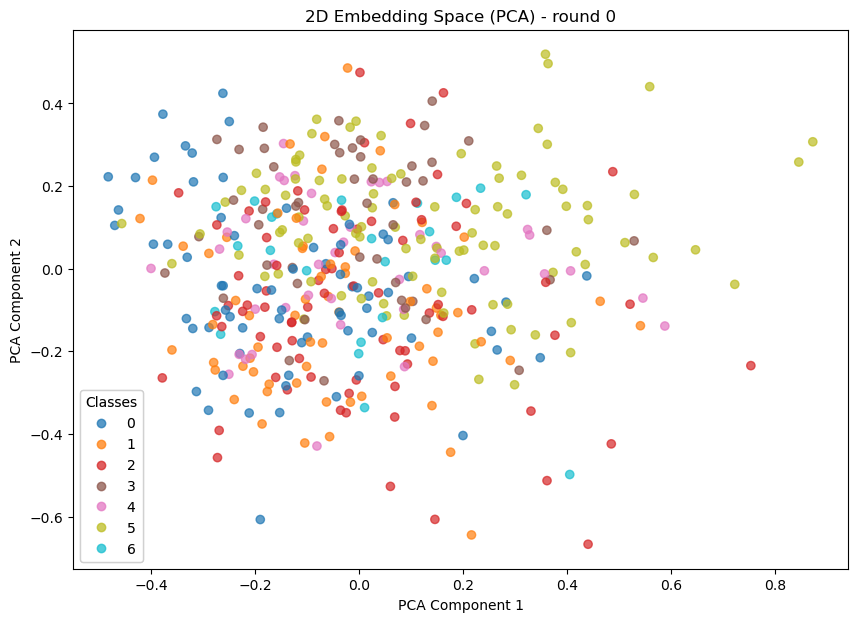

Embeddings shape: (420, 2)
Labels shape: (420,)


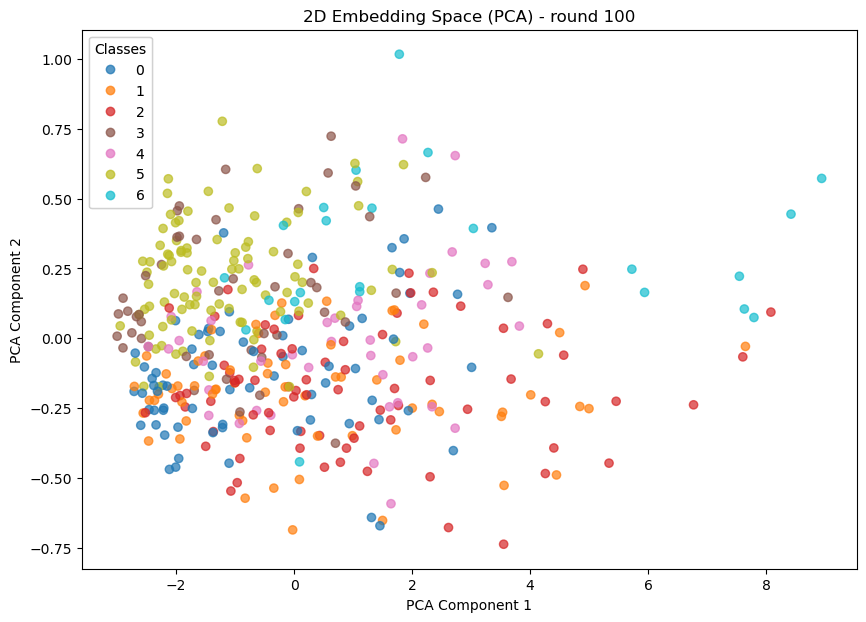

In [52]:
plot_embeddings(embeddings_2d=embeddings_2d_round_0, labels=labels_round_0, round=0)
plot_embeddings(embeddings_2d=embeddings_2d_round_100, labels=labels_round_100, round=100)

In [53]:
vectors_s_2d_round_0 = np.array([[-2.78527588e-01, -7.28276558e-03],
 [ 6.89582765e-01, -1.99603230e-01],
 [-3.32840085e-01, -1.38356924e-01],
 [ 1.21234789e-01,  6.49515152e-01],
 [ 2.96152115e-01,  6.51664063e-02],
 [ 1.21234775e-01,  6.49515212e-01],
 [-2.61137098e-01,  1.59395576e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [-2.57163286e-01, -1.45334348e-01],
 [-5.74948072e-01, -2.18370691e-01],
 [-3.06971371e-03, -3.08747739e-01],
 [ 6.89583123e-01, -1.99603230e-01],
 [-5.74948072e-01, -2.18370661e-01],
 [-1.59378588e-01,  1.32630989e-01],
 [ 6.89583123e-01, -1.99603245e-01],
 [-2.88005471e-01,  1.36017784e-01],
 [ 1.21234760e-01,  6.49515331e-01],
 [ 2.96152085e-01,  6.51663765e-02],
 [ 6.89583123e-01, -1.99603245e-01],
 [-3.32840055e-01, -1.38356835e-01],
 [-3.70766729e-01,  3.01010292e-02],
 [-3.70702624e-01, -1.53040662e-01],
 [-2.78527200e-01, -7.28283264e-03],
 [-3.06971371e-03, -3.08747709e-01],
 [-1.99651569e-01,  3.16095799e-02],
 [-2.67661959e-01,  7.03504542e-03],
 [ 6.89583123e-01, -1.99603245e-01],
 [-2.52821773e-01,  3.56412083e-02],
 [-1.00393653e-01, -2.56657034e-01],
 [-2.85362244e-01, -7.74042979e-02],
 [-1.24949776e-01, -2.06242651e-01],
 [ 6.89583123e-01, -1.99603245e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [ 6.89583123e-01, -1.99603245e-01],
 [-3.66350055e-01, -6.04560301e-02],
 [-5.74948072e-01, -2.18370646e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [-2.67661959e-01,  7.03504542e-03],
 [-3.32840055e-01, -1.38356850e-01],
 [-3.06971371e-03, -3.08747709e-01],
 [-1.37734845e-01, -1.94727182e-01],
 [-3.06971371e-03, -3.08747709e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [ 6.89583123e-01, -1.99603245e-01],
 [ 1.21234760e-01,  6.49515212e-01],
 [-7.80118406e-02, -5.48981912e-02],
 [ 6.89583123e-01, -1.99603245e-01],
 [-3.40176821e-01, -1.49884662e-02],
 [-3.06971371e-03, -3.08747709e-01],
 [-1.88566074e-01, -2.20936034e-02],
 [-6.12751842e-02,  1.00418534e-02],
 [ 3.07806909e-01,  4.06254977e-01],
 [-2.59734988e-01, -5.81597053e-02],
 [-2.74139374e-01,  6.64731190e-02],
 [-2.01232612e-01,  9.65724736e-02],
 [-3.95505130e-01, -7.03035593e-02],
 [-1.53175250e-01, -1.67816877e-01],
 [ 2.78423101e-01,  5.29225543e-02],
 [ 4.65993769e-02, -1.09183572e-01],
 [ 1.76791415e-01,  4.51229751e-01],
 [ 9.69995260e-02,  3.73268455e-01],
 [ 6.62747979e-01, -2.01006025e-01],
 [-1.26699507e-01,  7.13926926e-03],
 [-2.84296602e-01, -6.57663196e-02],
 [-3.34614217e-02,  2.43084639e-01],
 [ 9.07986984e-03, -1.22795738e-01],
 [ 4.71373975e-01, -4.33367342e-02],
 [-2.73133725e-01, -1.76618263e-01],
 [-2.16018721e-01,  9.01186839e-02],
 [ 3.67770903e-02, -8.10851436e-03],
 [-4.03507389e-02, -1.87143832e-01],
 [-3.49519998e-02,  3.34680229e-01],
 [-3.18156123e-01,  2.04138115e-01],
 [-3.01133931e-01, -2.74212807e-01],
 [ 4.64406639e-01, -1.45190701e-01],
 [-1.16052508e-01,  6.78688735e-02],
 [-5.43327443e-02, -3.22590292e-01],
 [-2.97728032e-01,  7.07335398e-02],
 [ 2.89763659e-01,  2.68779218e-01],
 [-3.95505130e-01, -7.03035593e-02],
 [ 6.62747979e-01, -2.01006025e-01],
 [ 3.67770903e-02, -8.10851436e-03],
 [-6.90100268e-02,  7.79976770e-02],
 [-2.89609909e-01, -2.28594262e-02],
 [-1.24358080e-01,  5.48434258e-02],
 [-1.05358772e-01,  6.12024311e-03],
 [ 2.22475842e-01, -2.76454687e-01],
 [-3.43058258e-01, -2.24392526e-02],
 [-2.76627779e-01, -3.43067527e-01],
 [-1.86061636e-01, -5.11004031e-02],
 [ 6.85295454e-05,  1.20400421e-01],
 [-4.12056953e-01, -1.16705418e-01],
 [ 5.79621494e-01, -1.36397770e-02],
 [ 4.07594413e-01, -3.62976611e-01],
 [ 5.00078440e-01,  2.89464723e-02],
 [-2.59734988e-01, -5.81597053e-02],
 [ 1.16537482e-01, -1.15648754e-01],
 [ 4.07594413e-01, -3.62976581e-01],
 [-1.48907602e-01,  4.13862392e-02]])



vectors_s_2d_round_100 = np.array([[-3.8558882e-01, -5.7243246e-01],
 [-3.8559365e-01, -5.7243282e-01],
 [-1.2469649e+00, -4.5962885e-02],
 [ 7.6563634e-02, -2.5748867e-01],
 [-2.0886230e+00, -3.7649241e-01],
 [-1.4550519e+00,  5.6349373e-01],
 [ 1.9899801e+00,  1.5262727e+00],
 [ 6.6800910e-01,  5.5599236e-01],
 [-5.8728814e-01,  1.3795919e-02],
 [-5.6249619e-01, -7.5877309e-02],
 [-2.1645145e+00, -3.8700396e-01],
 [ 5.0110340e+00, -7.1766394e-01],
 [ 1.7894702e+00,  1.5436157e+00],
 [-8.0247396e-01, -2.5149629e-01],
 [ 2.7284443e+00, -2.6039127e-01],
 [ 9.4749469e-01,  5.2457166e-01],
 [-1.4550519e+00,  5.6349361e-01],
 [ 1.7894702e+00,  1.5436157e+00],
 [-1.4550519e+00,  5.6349367e-01],
 [-2.1645145e+00, -3.8700396e-01],
 [-2.0886230e+00, -3.7649232e-01],
 [ 1.9899801e+00,  1.5262725e+00],
 [-1.8334868e+00, -4.2122436e-01],
 [-7.3870569e-01, -5.7299461e-02],
 [-3.8559195e-01, -5.7243294e-01],
 [-1.9537462e+00, -3.7953883e-01],
 [-1.1361169e+00, -2.7191341e-01],
 [ 3.2556686e-01,  2.4439138e-01],
 [ 2.7284443e+00, -2.6039127e-01],
 [ 1.7894702e+00,  1.5436157e+00],
 [-2.1645145e+00, -3.8700396e-01],
 [-1.4550519e+00,  5.6349367e-01],
 [-2.1645145e+00, -3.8700396e-01],
 [ 1.9899801e+00,  1.5262725e+00],
 [-1.1263278e+00, -5.9761807e-02],
 [ 2.7284443e+00, -2.6039127e-01],
 [-1.4550519e+00,  5.6349367e-01],
 [-1.4550519e+00,  5.6349367e-01],
 [-1.8334868e+00, -4.2122436e-01],
 [-8.0247396e-01, -2.5149626e-01],
 [-8.2934135e-01, -3.1398776e-01],
 [-3.8559195e-01, -5.7243294e-01],
 [ 8.5524493e-01, -1.0839055e-01],
 [ 1.7894702e+00,  1.5436157e+00],
 [-5.6249619e-01, -7.5877309e-02],
 [-1.4550519e+00,  5.6349367e-01],
 [ 5.0110340e+00, -7.1766394e-01],
 [-1.4550519e+00,  5.6349367e-01],
 [-3.8559195e-01, -5.7243294e-01],
 [-3.9996907e-01, -4.3999887e-01],
 [-1.0031919e+00,  2.8689238e-01],
 [-1.2313067e+00,  4.3774135e-02],
 [-1.0601753e+00, -5.8434913e-03],
 [-8.4998113e-01, -3.7716168e-01],
 [-8.2809716e-01,  1.4544347e-01],
 [-1.4626820e+00, -3.2775950e-02],
 [-1.1316303e+00, -1.6260663e-01],
 [-1.4626820e+00, -3.2775950e-02],
 [-1.5235467e+00,  6.2378906e-02],
 [ 4.4629002e-01,  1.8286249e-01],
 [-1.0261261e+00, -9.5331103e-02],
 [-8.9733690e-01, -1.3260640e-01],
 [-8.2111865e-01, -2.8287768e-01],
 [-9.6829897e-01, -2.5512180e-01],
 [-6.0247463e-01, -5.6262887e-01],
 [ 1.6642106e+00, -2.7493867e-01],
 [ 4.6656547e+00, -6.2899834e-01],
 [-1.5882007e+00, -1.3492750e-01],
 [ 1.4904391e+00, -2.4951436e-01],
 [ 4.6656547e+00, -6.2899834e-01],
 [-1.1436173e+00, -3.1808770e-01],
 [ 1.6521883e+00,  2.3434433e-01],
 [-6.8803507e-01,  2.6626161e-01],
 [-9.8661846e-01, -3.5031926e-02],
 [-1.2069739e+00, -1.0059330e-01],
 [ 5.4686213e+00, -8.9873642e-01],
 [-1.4997443e+00, -2.3860668e-01],
 [ 5.9718315e-02, -2.3674290e-01],
 [ 5.6198082e+00, -5.2730948e-01],
 [ 7.1478901e+00, -2.2150436e-02],
 [ 7.4908310e-01, -2.6159901e-02],
 [-1.3633783e+00, -2.2426461e-01],
 [ 6.4849007e-01,  1.5721388e-01],
 [-8.7705588e-01, -4.8549053e-01],
 [ 2.4166157e+00, -1.9625003e+00],
 [-1.0056245e+00,  4.2845380e-01],
 [-8.4998113e-01, -3.7716168e-01],
 [-1.3501971e+00, -2.1676436e-01],
 [-1.4464518e+00,  2.4938303e-01],
 [ 1.2921306e+00,  1.6015664e+00],
 [-6.2176174e-01,  1.7620403e-01],
 [-1.1533952e+00, -2.2462478e-01],
 [-1.3146503e+00, -1.0465427e-01],
 [ 5.4478321e+00, -1.5235426e-01],
 [-9.3860513e-01,  4.5007721e-01],
 [-1.2144408e+00, -2.2522974e-01],
 [-1.2077737e+00, -9.1144770e-02],
 [ 1.4394109e-01,  2.0369999e-01],
 [-1.0639766e+00, -1.7579134e-01],
 [-5.7849658e-01,  2.2317973e-01]])

In [54]:
markers_round_0 = np.array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

markers_round_100 = np.array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [55]:
similar_prototypes_2d_round_0 = np.array([[-0.20042701, -0.0341307 ],
 [ 0.30211532,  1.1379297 ]])

dissimilar_prototypes_2d_round_0 = np.array([[3.0188472, 1.5282848],
 [0.5138956, 2.1445994]])


similar_prototypes_2d_round_100 = np.array([[-2.8759491 , -0.42341608],
 [-2.3436673 ,  0.69916785]])

dissimilar_prototypes_2d_round_100 = np.array([[12.359312 ,  2.0044818],
 [11.994544 ,  1.598983 ]])

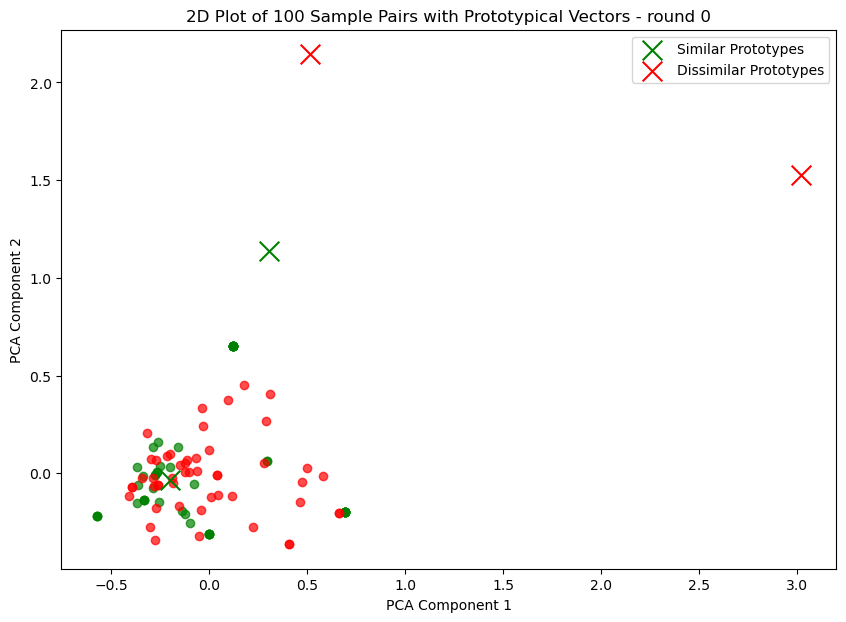

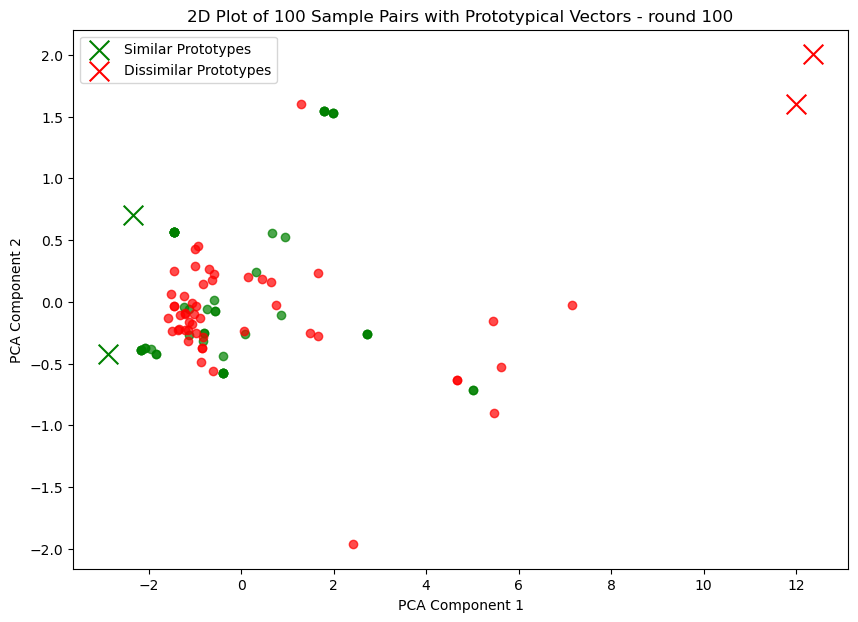

In [56]:
plot_markers(vectors_s_2d_round_0, markers_round_0, similar_prototypes_2d_round_0, dissimilar_prototypes_2d_round_0, round=0)
plot_markers(vectors_s_2d_round_100, markers_round_100, similar_prototypes_2d_round_100, dissimilar_prototypes_2d_round_100, round=100)